# NOTEBOOK 03 – LAM LINH | CHƯƠNG 3: DỮ LIỆU VÀ EDA

**Phụ trách:** 3.1–3.5 · Issue **#4**; phối hợp kiểm soát leakage Issue **#8**.
**Bàn giao schema/dataset cơ sở:** 12/11/2026. **Báo cáo Ch3:** 16/11/2026.

**Đầu vào:** 9 CSV Olist trong `data/raw/`; tải hợp lệ từ [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
**Đầu ra dùng chung:** `data/processed/orders_model_ready.csv` (không commit); kiểm tra QA + danh sách feature tại mốc duyệt.

[Lý thuyết Ch3](../docs/theory/03_lam_linh_ch3.md) · [DATA_CONTRACT](../docs/DATA_CONTRACT.md).

> Các cell có thể chạy khi dữ liệu Olist đã nằm trong data/raw. Không khẳng định đã xử lý xong hoặc gán kết quả khi chưa chạy.

# 0. Thiết lập môi trường
Xác định vị trí 9 CSV và tạo các thư mục lưu kết quả. Các hàm bên dưới được dùng chung cho các bước làm sạch.

In [38]:
from pathlib import Path
import json, hashlib, sys, platform, unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

NAMES = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
HERE = Path.cwd().resolve()
found = None
for candidate in (HERE, *HERE.parents):
    for raw_path in (candidate / 'data' / 'raw', candidate / 'data'):
        if all((raw_path / name).is_file() for name in NAMES.values()):
            found = (candidate, raw_path)
            break
    if found:
        break
if found is None:
    raise FileNotFoundError('Chưa tìm thấy đủ 9 CSV: giải nén vào data/raw/ hoặc data/ trong repo.')
ROOT, RAW = found
PROCESSED = ROOT / 'data' / 'processed'
CLEAN_DIR = PROCESSED / 'cleaned'
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
for path in (CLEAN_DIR, TABLES, FIGURES):
    path.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
plt.rcParams['figure.dpi'] = 110
LOG = []

def record(table, rule, affected, action):
    LOG.append({'table': table, 'rule': rule, 'affected': int(affected), 'action': action})

def start_clean(name):
    d = raw[name].copy()
    duplicate = d.duplicated()
    record(name, 'exact_duplicate_rows', duplicate.sum(), 'remove_exact_duplicates')
    d = d.loc[~duplicate].copy()
    for col in d.select_dtypes(include=['object', 'string']).columns:
        s = d[col].astype('string')
        d[col] = s.str.strip().replace('', pd.NA)
    return d

def require_key(d, columns, name):
    missing = d[columns].isna().any(axis=1)
    duplicate = d.duplicated(columns, keep=False)
    record(name, 'missing_key', missing.sum(), 'stop_if_present')
    record(name, 'duplicate_key_rows', duplicate.sum(), 'stop_if_present')
    if missing.any() or duplicate.any():
        d.loc[missing | duplicate].to_csv(TABLES / f'{name}_key_conflicts.csv', index=False)
        raise ValueError(f'{name}: khóa thiếu/trùng. Xem bảng xung đột; không tự giữ dòng đầu.')

def parse_dates(d, cols, name):
    for col in cols:
        source = d[col].copy()
        parsed = pd.to_datetime(source, errors='coerce')
        failed = source.notna() & parsed.isna()
        record(name, 'invalid_datetime:' + col, failed.sum(), 'coerce_to_NaT_and_report')
        d[col] = parsed

def to_number(d, cols, name):
    for col in cols:
        source = d[col].copy()
        converted = pd.to_numeric(source, errors='coerce')
        record(name, 'numeric_parse_failure:' + col,
               (source.notna() & converted.isna()).sum(), 'coerce_to_NA_and_report')
        d[col] = converted

def normalize_location(d, prefix, name):
    # Không bỏ dấu/đổi tên địa danh tùy ý. Mã ZIP prefix luôn là chuỗi 5 chữ số.
    zip_col, city_col, state_col = prefix + '_zip_code_prefix', prefix + '_city', prefix + '_state'
    s = d[zip_col].astype('string').str.strip()
    valid = s.str.fullmatch(r'\d{1,5}').fillna(False)
    d['qa_invalid_zip'] = ~valid
    record(name, 'invalid_zip_prefix', (~valid).sum(), 'set_NA_keep_flag')
    d[zip_col] = s.where(valid).str.zfill(5)
    d[city_col] = d[city_col].astype('string').str.normalize('NFC').str.lower().str.replace(r'\s+', ' ', regex=True)
    d[state_col] = d[state_col].astype('string').str.upper()
    states = set('AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split())
    d['qa_invalid_state'] = ~d[state_col].isin(states)
    record(name, 'invalid_state', d['qa_invalid_state'].sum(), 'keep_flag_for_review')
    return d

print('Thư mục dự án:', ROOT.name, '| đầu vào:', RAW.relative_to(ROOT))
print('Python:', platform.python_version(), '| pandas:', pd.__version__)


Thư mục dự án: Do_An_Khoa_hoc_du_lieu---GR02 | đầu vào: data\raw
Python: 3.14.0 | pandas: 2.3.3


# 3.1 Nguồn dữ liệu, cấu trúc và đọc file

**Nội dung báo cáo:** nguồn dataset, bản chất giao dịch Olist Brazil 2016–2018, 9 bảng và các khóa (`order_id`, `customer_id`, `product_id`, `seller_id`). Chỉ tóm tắt số dòng/biến **sau khi tự chạy** cell kiểm kê.

**Ràng buộc:** dữ liệu gốc không đưa lên GitHub.

In [39]:
raw = {}
source_records = []
for name, filename in NAMES.items():
    path = RAW / filename
    columns = pd.read_csv(path, nrows=0).columns
    string_cols = {c: 'string' for c in columns
                   if (c.endswith('_id') and c != 'order_item_id') or 'zip_code_prefix' in c}
    raw[name] = pd.read_csv(path, dtype=string_cols)
    source_records.append({'table': name, 'file': filename,
                           'bytes': path.stat().st_size,
                           'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
profile = pd.DataFrame([{
    'table': name, 'rows': len(d), 'columns': len(d.columns),
    'duplicate_rows': int(d.duplicated().sum()),
    'missing_cells': int(d.isna().sum().sum())
} for name, d in raw.items()])
column_profile = pd.DataFrame([{
    'table': name, 'column': c, 'dtype': str(d[c].dtype),
    'missing': int(d[c].isna().sum()), 'missing_pct': round(100*d[c].isna().mean(), 3),
    'n_unique': int(d[c].nunique())
} for name, d in raw.items() for c in d.columns])
profile.to_csv(TABLES / 'raw_profile.csv', index=False)
column_profile.to_csv(TABLES / 'raw_column_profile.csv', index=False)
pd.DataFrame(source_records).to_csv(TABLES / 'source_manifest.csv', index=False)
display(profile)
display(column_profile.loc[column_profile['missing'] > 0])


,table,rows,columns,duplicate_rows,missing_cells
0,orders,99441,8,0,4908
1,items,112650,7,0,0
2,customers,99441,5,0,0
3,sellers,3095,4,0,0
4,products,32951,9,0,2448
5,payments,103886,5,0,0
6,reviews,99224,7,0,145903
7,geolocation,1000163,5,261831,0
8,translation,71,2,0,0


,table,column,dtype,missing,missing_pct,n_unique
4,orders,order_approved_at,object,160,0.161,90733
5,orders,order_delivered_carrier_date,object,1783,1.793,81018
6,orders,order_delivered_customer_date,object,2965,2.982,95664
25,products,product_category_name,object,610,1.851,73
26,products,product_name_lenght,float64,610,1.851,66
27,products,product_description_lenght,float64,610,1.851,2960
28,products,product_photos_qty,float64,610,1.851,19
29,products,product_weight_g,float64,2,0.006,2204
30,products,product_length_cm,float64,2,0.006,99
31,products,product_height_cm,float64,2,0.006,102


Nhận xét: geolocation có nhiều dòng nhất (1.000.163), trong đó 261.831 dòng trùng hoàn toàn. reviews có 145.903 ô thiếu, tập trung ở tiêu đề và nội dung bình luận; đây là các trường không bắt buộc. orders còn 4.908 ô thiếu, products còn 2.448 ô thiếu. Vì vậy cần làm sạch theo ý nghĩa của từng cột, không xóa tất cả dòng có giá trị rỗng.

Khóa nối chính: order_id ở orders; cặp order_id–`order_item_id` ở items; customer_id, product_id, seller_id ở các bảng tương ứng. Một đơn có thể có nhiều sản phẩm hoặc nhiều lần thanh toán nên không xem order_id lặp ở những bảng này là lỗi.

# 3.2. Làm sạch từng bảng
**Rủi ro quan trọng:** `order_items` có nhiều dòng/order, `geolocation` có thể nhiều dòng/zip prefix. **Không join trực tiếp để một đơn thành nhiều dòng rồi tính KPI sai.**

Trong phiên bản khung này, chúng ta tổng hợp `order_items` theo `order_id`, sau đó merge với bảng `orders`, `customers`. Các dữ liệu sản phẩm/seller phục vụ **EDA và feature ứng viên**, chưa tự động được sử dụng để dự báo sớm nếu thiếu bằng chứng biết được tại `order_approved_at`.
## 3.2.1. Orders – đơn hàng
Chuẩn hóa trạng thái và các cột thời gian, sau đó đánh dấu những mốc thời gian không hợp lý. Chưa xóa đơn chỉ vì có cờ bất thường.

In [40]:
orders = start_clean('orders')
require_key(orders, ['order_id'], 'orders')
orders['order_status'] = orders['order_status'].astype('string').str.lower()
valid_status = {'delivered', 'shipped', 'canceled', 'unavailable', 'invoiced', 'processing', 'created', 'approved'}
orders['qa_unknown_status'] = ~orders['order_status'].isin(valid_status)
parse_dates(orders, ['order_purchase_timestamp', 'order_approved_at',
                    'order_delivered_carrier_date', 'order_delivered_customer_date',
                    'order_estimated_delivery_date'], 'orders')
orders['qa_approved_before_purchase'] = orders['order_approved_at'] < orders['order_purchase_timestamp']
orders['qa_carrier_before_approved'] = orders['order_delivered_carrier_date'] < orders['order_approved_at']
orders['qa_delivery_before_carrier'] = orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']
orders['qa_delivery_before_approved'] = orders['order_delivered_customer_date'] < orders['order_approved_at']
orders['qa_delivery_before_purchase'] = orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']
orders['qa_estimate_before_purchase'] = orders['order_estimated_delivery_date'].dt.normalize() < orders['order_purchase_timestamp'].dt.normalize()
for c in orders.filter(like='qa_').columns:
    record('orders', c, orders[c].sum(), 'keep_flag_review_before_changing_cohort')
display(orders['order_status'].value_counts(dropna=False).rename('orders').to_frame())
display(orders.filter(like='qa_').sum().rename('flagged_rows').to_frame())


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,flagged_rows
qa_unknown_status,0
qa_approved_before_purchase,0
qa_carrier_before_approved,1359
qa_delivery_before_carrier,23
qa_delivery_before_approved,61
qa_delivery_before_purchase,0
qa_estimate_before_purchase,0


Nhận xét: Có 96.478/99.441 đơn ở trạng thái delivered. Không có trạng thái lạ, nhưng có 1.359 bản ghi bàn giao vận chuyển trước thời điểm duyệt, 23 bản ghi giao khách trước khi bàn giao vận chuyển và 61 bản ghi giao khách trước khi duyệt. Các nhóm này có thể trùng nhau nên không cộng thành tổng số đơn lỗi. Giữ cờ để nhóm kiểm tra trước khi quyết định loại mẫu.
## 3.2.2. Items – sản phẩm trong đơn hàng
Kiểm tra khóa ghép, giá, phí vận chuyển và ngày giới hạn gửi hàng.

In [41]:
items = start_clean('items')
to_number(items, ['order_item_id', 'price', 'freight_value'], 'items')
require_key(items, ['order_id', 'order_item_id'], 'items')
parse_dates(items, ['shipping_limit_date'], 'items')
items['qa_invalid_item_number'] = items['order_item_id'].isna() | (items['order_item_id'] < 1) | (items['order_item_id'] % 1 != 0)
items['qa_nonpositive_price'] = items['price'].isna() | (items['price'] <= 0)
items['qa_negative_freight'] = items['freight_value'] < 0
items['qa_missing_product_or_seller'] = items[['product_id', 'seller_id']].isna().any(axis=1)
for c in items.filter(like='qa_').columns:
    record('items', c, items[c].sum(), 'keep_flag_for_review')
display(items[['price', 'freight_value']].describe(percentiles=[.5,.95,.99]))
print('Item có phí vận chuyển bằng 0, giữ lại:', int(items['freight_value'].eq(0).sum()))


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
50%,74.990000,16.260000
95%,349.900000,45.120000
99%,890.000000,84.520000
max,6735.000000,409.680000


Item có phí vận chuyển bằng 0, giữ lại: 383


Nhận xét: Giá sản phẩm có trung vị 74,99 BRL và trung bình 120,65 BRL, cho thấy có những mặt hàng giá cao kéo trung bình lên. Có 383 dòng phí vận chuyển bằng 0; các dòng này được giữ vì chưa có căn cứ xem phí 0 là sai. Không phát hiện giá âm trong thống kê hiển thị.
## 3.2.3. Customers – khách hàng
Kiểm tra khóa khách hàng, chuẩn hóa mã ZIP, tên thành phố và mã bang.

In [42]:
customers = start_clean('customers')
require_key(customers, ['customer_id'], 'customers')
customers = normalize_location(customers, 'customer', 'customers')
print('Số bản ghi customer:', len(customers))
print('Số khách phân biệt theo customer_unique_id:', customers['customer_unique_id'].nunique())
display(customers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


Số bản ghi customer: 99441
Số khách phân biệt theo customer_unique_id: 96096


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0


Nhận xét: Bảng có 99.441 bản ghi khách hàng, tương ứng 96.096 mã customer_unique_id khác nhau. Một người có thể mua nhiều đơn, nên không xóa các mã khách hàng lặp theo customer_unique_id. Không phát hiện ZIP hoặc mã bang không hợp lệ theo quy tắc đang kiểm tra.
## 3.2.4. Sellers – người bán
Chuẩn hóa thông tin địa lý và kiểm tra seller_id.

In [43]:
sellers = start_clean('sellers')
require_key(sellers, ['seller_id'], 'sellers')
sellers = normalize_location(sellers, 'seller', 'sellers')
print('Số người bán:', len(sellers))
display(sellers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


Số người bán: 3095


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0


Nhận xét: Có 3.095 người bán. Không ghi nhận mã ZIP hoặc mã bang không hợp lệ theo phép kiểm tra hiện tại, nên không có bản ghi nào bị loại ở bước này.
## 3.2.5. Products – sản phẩm
Kiểm tra các thuộc tính mô tả sản phẩm; giữ nguyên cột gốc và đánh dấu các giá trị bất thường.

In [44]:
products = start_clean('products')
require_key(products, ['product_id'], 'products')
product_numeric = ['product_name_lenght','product_description_lenght','product_photos_qty',
                   'product_weight_g','product_length_cm','product_height_cm','product_width_cm']
to_number(products, product_numeric, 'products')
products['qa_missing_category'] = products['product_category_name'].isna()
for c in ['product_weight_g','product_length_cm','product_height_cm','product_width_cm']:
    products[c + '_raw'] = products[c]
    invalid = products[c].notna() & (products[c] <= 0)
    products['qa_nonpositive_' + c] = invalid
    products.loc[invalid, c] = np.nan
    record('products', 'nonpositive:' + c, invalid.sum(), 'set_NA_keep_original_raw_column')
for c in ['product_name_lenght','product_description_lenght','product_photos_qty']:
    products['qa_invalid_' + c] = products[c].notna() & ((products[c] < 0) | (products[c] % 1 != 0))
display(products[['product_category_name'] + product_numeric].isna().sum().rename('missing_after').to_frame())
print('Trọng lượng 0/âm đã chuyển thành thiếu:', int(products['qa_nonpositive_product_weight_g'].sum()))


,missing_after
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,6
product_length_cm,2
product_height_cm,2
product_width_cm,2


Trọng lượng 0/âm đã chuyển thành thiếu: 4


Nhận xét: Có 610 sản phẩm thiếu danh mục và đồng thời thiếu các thông tin độ dài tên, mô tả, số ảnh. Trọng lượng ban đầu thiếu 2 dòng; thêm 4 dòng có trọng lượng bằng 0 hoặc âm được chuyển thành thiếu, nên sau xử lý có 6 dòng thiếu trọng lượng. Không tự điền giá trị vì chưa có cơ sở xác định trọng lượng thực tế.
## 3.2.6. Payments – thanh toán
Kiểm tra thứ tự thanh toán, hình thức thanh toán, số kỳ và giá trị tiền.

In [45]:
payments = start_clean('payments')
to_number(payments, ['payment_sequential','payment_installments','payment_value'], 'payments')
require_key(payments, ['order_id','payment_sequential'], 'payments')
payments['payment_type'] = payments['payment_type'].astype('string').str.lower()
payments['qa_unknown_payment_type'] = ~payments['payment_type'].isin(['credit_card','boleto','voucher','debit_card','not_defined'])
payments['qa_not_defined'] = payments['payment_type'].eq('not_defined').fillna(False)
payments['qa_zero_value'] = payments['payment_value'].eq(0)
payments['qa_zero_installments'] = payments['payment_installments'].eq(0)
payments['qa_invalid_value'] = payments['payment_value'].isna() | payments['payment_value'].lt(0)
payments['qa_invalid_installments'] = payments['payment_installments'].isna() | payments['payment_installments'].lt(0) | (payments['payment_installments'] % 1 != 0)
payments['qa_invalid_sequential'] = payments['payment_sequential'].isna() | payments['payment_sequential'].lt(1) | (payments['payment_sequential'] % 1 != 0)
for c in payments.filter(like='qa_').columns:
    record('payments', c, payments[c].sum(), 'keep_flag_for_review')
display(payments.filter(like='qa_').sum().rename('flagged_rows').to_frame())
display(payments['payment_type'].value_counts(dropna=False).to_frame('records'))


,flagged_rows
qa_unknown_payment_type,0
qa_not_defined,3
qa_zero_value,9
qa_zero_installments,2
qa_invalid_value,0
qa_invalid_installments,0
qa_invalid_sequential,0


,records
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


Nhận xét: Thanh toán bằng credit_card chiếm số lượng nhiều nhất (76.795 bản ghi). Có 3 bản ghi not_defined, 9 bản ghi số tiền bằng 0 và 2 bản ghi số kỳ trả góp bằng 0. Đây là các trường hợp cần rà soát, chưa tự ý xóa hoặc sửa giá trị.
## 3.2.7. Reviews – đánh giá đơn hàng
Kiểm tra điểm đánh giá, thời gian tạo/trả lời và nội dung bình luận.

In [46]:
reviews = start_clean('reviews')
require_key(reviews, ['review_id','order_id'], 'reviews')
to_number(reviews, ['review_score'], 'reviews')
parse_dates(reviews, ['review_creation_date','review_answer_timestamp'], 'reviews')
reviews['qa_invalid_review_score'] = reviews['review_score'].isna() | ~reviews['review_score'].between(1,5) | (reviews['review_score'] % 1 != 0)
reviews['qa_answer_before_creation'] = reviews['review_answer_timestamp'] < reviews['review_creation_date']
reviews['has_comment_title'] = reviews['review_comment_title'].notna()
reviews['has_comment_message'] = reviews['review_comment_message'].notna()
for c in reviews.filter(like='qa_').columns:
    record('reviews', c, reviews[c].sum(), 'keep_flag_for_review')
print('Số dòng review_id lặp vượt lần đầu:', int(reviews['review_id'].duplicated().sum()))
print('Số dòng order_id lặp vượt lần đầu:', int(reviews['order_id'].duplicated().sum()))
display(reviews[['review_comment_title','review_comment_message']].isna().sum().to_frame('missing'))
display(reviews.filter(like='qa_').sum().to_frame('flagged_rows'))


Số dòng review_id lặp vượt lần đầu: 814
Số dòng order_id lặp vượt lần đầu: 551


,missing
review_comment_title,87658
review_comment_message,58274


,flagged_rows
qa_invalid_review_score,0
qa_answer_before_creation,0


Nhận xét: Sau khi chuẩn hóa chuỗi rỗng, có 87.658 tiêu đề và 58.274 nội dung bình luận bị thiếu; số này tăng nhẹ so với dữ liệu gốc do một số ô chỉ chứa khoảng trắng. Không thấy điểm đánh giá ngoài khoảng 1–5 hoặc thời gian trả lời sớm hơn ngày tạo. review_id có 814 lần lặp vượt lần xuất hiện đầu, order_id có 551 lần lặp; cần hiểu cấu trúc đánh giá, không xóa chỉ vì một trong hai mã lặp.
## 3.2.8. Geolocation – dữ liệu địa lý
Bỏ dòng trùng hoàn toàn, kiểm tra tọa độ và lập bảng tọa độ đại diện cho từng mã ZIP.

In [47]:
geolocation = start_clean('geolocation')
geolocation = normalize_location(geolocation, 'geolocation', 'geolocation')
to_number(geolocation, ['geolocation_lat','geolocation_lng'], 'geolocation')
geolocation['qa_invalid_world_coordinate'] = (~geolocation['geolocation_lat'].between(-90,90)
                                             | ~geolocation['geolocation_lng'].between(-180,180))
geolocation['qa_outside_brazil_screen'] = (~geolocation['geolocation_lat'].between(-34,6)
                                          | ~geolocation['geolocation_lng'].between(-74,-34))
for c in ['qa_invalid_world_coordinate','qa_outside_brazil_screen']:
    record('geolocation', c, geolocation[c].sum(), 'retain_in_clean_exclude_from_zip_representative')
usable_geo = geolocation.loc[~geolocation['qa_invalid_world_coordinate']
                            & ~geolocation['qa_outside_brazil_screen']
                            & ~geolocation['qa_invalid_zip']]
geo_by_zip = usable_geo.groupby('geolocation_zip_code_prefix', as_index=False).agg(
    latitude=('geolocation_lat','median'), longitude=('geolocation_lng','median'),
    coordinate_records=('geolocation_lat','size'))
assert geo_by_zip['geolocation_zip_code_prefix'].is_unique
geo_by_zip.to_csv(PROCESSED / 'geolocation_by_zip.csv', index=False)
print('Dòng gốc:', len(raw['geolocation']), '| sau bỏ trùng:', len(geolocation))
display(geolocation.filter(like='qa_').sum().to_frame('flagged_rows'))
print('ZIP có tọa độ đại diện hợp lệ:', len(geo_by_zip))


Dòng gốc: 1000163 | sau bỏ trùng: 738332


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0
qa_invalid_world_coordinate,0
qa_outside_brazil_screen,33


ZIP có tọa độ đại diện hợp lệ: 19010


Nhận xét: Bảng giảm từ 1.000.163 xuống 738.332 dòng sau khi bỏ 261.831 dòng trùng hoàn toàn. Có 33 tọa độ nằm ngoài khoảng sàng lọc rộng đang dùng cho Brazil; các dòng vẫn được giữ trong bảng sạch và không đưa vào tính tọa độ ZIP đại diện. Sau lọc, tạo được 19.010 mã ZIP có tọa độ đại diện. Khoảng sàng lọc chỉ để kiểm tra nhanh, không phải ranh giới hành chính chính xác.
## 3.2.9. Translation – dịch danh mục sản phẩm
Đối chiếu danh mục sản phẩm với bảng dịch sang tiếng Anh.

In [48]:
translation = start_clean('translation')
for c in ['product_category_name','product_category_name_english']:
    translation[c] = translation[c].astype('string').str.lower()
require_key(translation, ['product_category_name'], 'translation')
translation['qa_missing_english'] = translation['product_category_name_english'].isna()
untranslated = (products.loc[products['product_category_name'].notna()
                 & ~products['product_category_name'].isin(translation['product_category_name']),
                 'product_category_name'].value_counts().rename_axis('category').reset_index(name='products'))
untranslated.to_csv(TABLES / 'untranslated_categories.csv', index=False)
display(untranslated)
print('Bản dịch thiếu tiếng Anh:', int(translation['qa_missing_english'].sum()))


,category,products
0,portateis_cozinha_e_preparadores_de_alimentos,10
1,pc_gamer,3


Bản dịch thiếu tiếng Anh: 0


Nhận xét: Không có bản dịch thiếu tiếng Anh trong bảng translation, nhưng có 2 danh mục sản phẩm không tìm thấy bản dịch: portateis_cozinha_e_preparadores_de_alimentos (10 sản phẩm) và pc_gamer (3 sản phẩm). Giữ lại tên danh mục gốc, không tự tạo bản dịch.
## 3.2.10. Đối soát và lưu 9 bảng sạch
Kiểm tra khóa ngoại giữa các bảng và số dòng trước/sau làm sạch.

In [49]:
clean = dict(orders=orders, items=items, customers=customers, sellers=sellers,
             products=products, payments=payments, reviews=reviews,
             geolocation=geolocation, translation=translation)
relations = [
    ('orders','customer_id','customers','customer_id'),
    ('items','order_id','orders','order_id'),
    ('items','product_id','products','product_id'),
    ('items','seller_id','sellers','seller_id'),
    ('payments','order_id','orders','order_id'),
    ('reviews','order_id','orders','order_id'),
]
fk_rows=[]
for child, ck, parent, pk in relations:
    s=clean[child][ck]
    fk_rows.append({'child':child, 'key':ck, 'parent':parent,
                    'missing_key':int(s.isna().sum()),
                    'orphan_rows':int((s.notna() & ~s.isin(clean[parent][pk])).sum())})
fk_report=pd.DataFrame(fk_rows)
fk_report.to_csv(TABLES/'foreign_key_audit.csv',index=False)
display(fk_report)
assert fk_report[['missing_key','orphan_rows']].to_numpy().sum() == 0, 'Có khóa ngoại chưa giải quyết; xem báo cáo.'
summary=[]
for name,d in clean.items():
    original_cols=raw[name].columns
    filename=Path(NAMES[name]).stem + '_clean.csv'
    d.to_csv(CLEAN_DIR/filename,index=False)
    summary.append({'table':name,'rows_before':len(raw[name]),'rows_after':len(d),
                    'removed_rows':len(raw[name])-len(d),
                    'missing_before':int(raw[name].isna().sum().sum()),
                    'missing_after_original_columns':int(d[original_cols].isna().sum().sum()),
                    'qa_flag_columns':len(d.filter(like='qa_').columns)})
clean_summary=pd.DataFrame(summary)
clean_summary.to_csv(TABLES/'cleaning_summary.csv',index=False)
pd.DataFrame(LOG).to_csv(TABLES/'cleaning_log.csv',index=False)
display(clean_summary)
assert len(clean)==9
print('Đã xuất 9 bảng sạch tại:', CLEAN_DIR.relative_to(ROOT))


,child,key,parent,missing_key,orphan_rows
0,orders,customer_id,customers,0,0
1,items,order_id,orders,0,0
2,items,product_id,products,0,0
3,items,seller_id,sellers,0,0
4,payments,order_id,orders,0,0
5,reviews,order_id,orders,0,0


,table,rows_before,rows_after,removed_rows,missing_before,missing_after_original_columns,qa_flag_columns
0,orders,99441,99441,0,4908,4908,7
1,items,112650,112650,0,0,0,4
2,customers,99441,99441,0,0,0,2
3,sellers,3095,3095,0,0,0,2
4,products,32951,32951,0,2448,2452,8
5,payments,103886,103886,0,0,0,7
6,reviews,99224,99224,0,145903,145932,2
7,geolocation,1000163,738332,261831,0,0,4
8,translation,71,71,0,0,0,1


Đã xuất 9 bảng sạch tại: data\processed\cleaned


Nhận xét: Cả 6 quan hệ khóa ngoại được kiểm tra đều không có khóa thiếu hoặc bản ghi mồ côi. Trong 9 bảng, chỉ geolocation giảm số dòng do bỏ trùng; các bảng khác giữ nguyên số dòng. Số ô thiếu ở products và reviews tăng nhẹ vì chuẩn hóa giá trị không hợp lệ hoặc chuỗi trắng thành thiếu, không có nghĩa dữ liệu bị mất ngoài kiểm soát.
# 3.3. Gộp dữ liệu và tạo nhãn

**Nhãn:** `is_late=1` khi `DATE(delivered_customer) > DATE(estimated_delivery)`. Chỉ những đơn *delivered*, có phê duyệt và 2 ngày hợp lệ mới có nhãn 0/1.

**Không gán nhãn 0 cho cancelled/unavailable**, ghi rõ số mẫu bị loại và tác động delivered-only selection bias.
## 3.3.1. Gộp theo đơn hàng
Tổng hợp nhiều sản phẩm và nhiều giao dịch về một dòng order_id trước khi nối với bảng đơn hàng.

In [50]:
def summarize_distinct(s):
    values=sorted(s.dropna().astype(str).unique())
    return values[0] if len(values)==1 else ('MULTI' if len(values)>1 else 'UNKNOWN')

enriched=(items.merge(products[['product_id','product_category_name','product_weight_g']],
                       on='product_id',how='left',validate='many_to_one')
          .merge(sellers[['seller_id','seller_state']],on='seller_id',how='left',validate='many_to_one'))
item_agg=enriched.groupby('order_id',as_index=False).agg(
    item_count=('order_item_id','size'), product_count=('product_id','nunique'),
    seller_count=('seller_id','nunique'), total_price=('price',lambda s:s.sum(min_count=1)),
    total_freight=('freight_value',lambda s:s.sum(min_count=1)),
    price_known_items=('price','count'), freight_known_items=('freight_value','count'),
    avg_weight_g=('product_weight_g','mean'), weight_known_items=('product_weight_g','count'),
    seller_region=('seller_state',summarize_distinct),
    product_category=('product_category_name',summarize_distinct))
payment_agg=payments.groupby('order_id',as_index=False).agg(
    total_payment=('payment_value',lambda s:s.sum(min_count=1)),
    payment_records=('payment_sequential','size'))
base=(orders.merge(customers[['customer_id','customer_state']],on='customer_id',how='left',validate='many_to_one')
      .merge(item_agg,on='order_id',how='left',validate='one_to_one')
      .merge(payment_agg,on='order_id',how='left',validate='one_to_one'))
assert base['order_id'].is_unique and base['order_id'].notna().all()
assert len(base)==len(orders)
join_audit=pd.DataFrame([
    {'metric':'orders_before_join','count':len(orders)},
    {'metric':'orders_after_join','count':len(base)},
    {'metric':'orders_without_items','count':int(base['item_count'].isna().sum())},
    {'metric':'orders_without_payment','count':int(base['payment_records'].isna().sum())},
    {'metric':'orders_with_multiple_sellers','count':int(base['seller_count'].gt(1).sum())},
])
join_audit.to_csv(TABLES/'join_audit.csv',index=False)
display(join_audit)
# Bảng nối đơn-người bán dành cho EDA riêng, không đưa vào mô hình cấp đơn.
order_seller=enriched[['order_id','seller_id']].drop_duplicates()


,metric,count
0,orders_before_join,99441
1,orders_after_join,99441
2,orders_without_items,775
3,orders_without_payment,1
4,orders_with_multiple_sellers,1278


Nhận xét: Sau khi nối, dữ liệu vẫn có 99.441 đơn, không phát sinh thêm dòng. Có 775 đơn không có chi tiết sản phẩm, 1 đơn không có thanh toán và 1.278 đơn có nhiều người bán. Các trường hợp này được ghi nhận để tránh làm sai số lượng đơn khi phân tích.
## 3.3.2. Tạo nhãn is_late
Chỉ gán nhãn cho đơn delivered có đủ ngày duyệt, ngày giao thực tế và ngày giao dự kiến. is_late = 1 khi ngày giao thực tế muộn hơn ngày dự kiến, ngược lại bằng 0. So theo ngày, không so giờ.

In [51]:
conditions=[
    ('not_delivered',base['order_status'].eq('delivered')),
    ('missing_approved_at',base['order_approved_at'].notna()),
    ('missing_actual_delivery',base['order_delivered_customer_date'].notna()),
    ('missing_estimated_delivery',base['order_estimated_delivery_date'].notna()),
]
remaining=pd.Series(True,index=base.index)
exclusion=[]
for reason, valid in conditions:
    valid=valid.fillna(False)
    removed=remaining & ~valid
    exclusion.append({'reason':reason,'excluded_orders':int(removed.sum())})
    remaining &= valid
base['is_late']=pd.Series(pd.NA,index=base.index,dtype='Int64')
base.loc[remaining,'is_late']=(
    base.loc[remaining,'order_delivered_customer_date'].dt.normalize()
    > base.loc[remaining,'order_estimated_delivery_date'].dt.normalize()).astype('int64')
model_data=base.loc[remaining].copy()
model_data['is_late']=model_data['is_late'].astype(int)
exclusion_table=pd.DataFrame(exclusion)
assert int(exclusion_table['excluded_orders'].sum())+len(model_data)==len(base)
assert model_data['order_id'].is_unique and model_data['is_late'].isin([0,1]).all()
label_audit=pd.DataFrame([{'all_orders':len(base),'labeled_orders':len(model_data),
                         'unlabeled_orders':len(base)-len(model_data),
                         'late_orders':int(model_data['is_late'].sum()),
                         'late_rate':model_data['is_late'].mean()}])
exclusion_table.to_csv(TABLES/'label_exclusions.csv',index=False)
label_audit.to_csv(TABLES/'label_audit.csv',index=False)
display(exclusion_table)
display(label_audit)
# Kiểm tra độ nhạy mô tả, CHƯA thay đổi tập mô hình chính.
time_flags=['qa_approved_before_purchase','qa_carrier_before_approved',
            'qa_delivery_before_carrier','qa_delivery_before_approved',
            'qa_delivery_before_purchase','qa_estimate_before_purchase']
flagged=model_data[time_flags].any(axis=1)
sensitivity=pd.DataFrame([
    {'cohort':'main_contract','orders':len(model_data),'late_rate':model_data['is_late'].mean()},
    {'cohort':'exclude_any_chronology_flag_for_review','orders':int((~flagged).sum()),
     'late_rate':model_data.loc[~flagged,'is_late'].mean()}
])
sensitivity.to_csv(TABLES/'chronology_sensitivity.csv',index=False)
display(sensitivity)


,reason,excluded_orders
0,not_delivered,2963
1,missing_approved_at,14
2,missing_actual_delivery,8
3,missing_estimated_delivery,0


,all_orders,labeled_orders,unlabeled_orders,late_orders,late_rate
0,99441,96456,2985,6534,0.067741


,cohort,orders,late_rate
0,main_contract,96456,0.067741
1,exclude_any_chronology_flag_for_review,95083,0.068466


Nhận xét: Từ 99.441 đơn, loại 2.963 đơn chưa ở trạng thái delivered, 14 đơn thiếu ngày duyệt và 8 đơn thiếu ngày giao thực tế (theo thứ tự lọc). Còn 96.456 đơn có nhãn, trong đó 6.534 đơn giao trễ, chiếm 6,77%. Nếu tạm loại các đơn có cờ bất thường thời gian, mẫu còn 95.083 đơn với tỷ lệ trễ 6,85%; đây chỉ là kiểm tra độ nhạy, chưa thay đổi tập dữ liệu chính.
# 3.4. Phân tích dữ liệu sau làm sạch (EDA)
Đề xuất EDA thực tế: phân phối số đơn theo tháng, tỷ lệ giao trễ theo bang người mua, theo vùng seller (MULTI tách riêng), nhóm hàng và trọng lượng. **Báo cáo luôn số lượng đơn cùng tỷ lệ**, tránh suy luận nhóm nhỏ đại diện cả ngành.

Viết 3–5 insight sau khi đọc biểu đồ; không tự diễn giải trước khi chạy.

In [52]:
model_data['purchase_month']=model_data['order_purchase_timestamp'].dt.to_period('M').astype('string')
# Các bin cố định phục vụ mô tả, không học từ Test.
model_data['order_value_group']=pd.cut(model_data['total_price'],[-np.inf,50,100,200,500,np.inf],
                                      labels=['<=50','50-100','100-200','200-500','>500'])
model_data['weight_group']=pd.cut(model_data['avg_weight_g'],[-np.inf,500,1000,5000,np.inf],
                                 labels=['<=500g','500-1000g','1000-5000g','>5000g'])
def late_table(d,group):
    return d.groupby(group,dropna=False,observed=True).agg(
        orders=('order_id','nunique'),late_orders=('is_late','sum'),
        late_rate=('is_late','mean')).reset_index()
eda={}
for group in ['purchase_month','customer_state','seller_region','product_category','order_value_group','weight_group']:
    eda[group]=late_table(model_data,group)
    eda[group].to_csv(TABLES/f'eda_{group}.csv',index=False)
seller_detail=order_seller.merge(model_data[['order_id','is_late']],on='order_id',how='inner',validate='many_to_one')
eda_seller=late_table(seller_detail,'seller_id')
eda_seller.to_csv(TABLES/'eda_seller_id.csv',index=False)
print('Theo seller_id: mỗi đơn được tính tối đa một lần trong từng seller; đơn nhiều seller có thể xuất hiện ở nhiều nhóm.')
print('Vì vậy không cộng số đơn giữa các seller để suy ra tổng đơn toàn bộ.')
display(eda['customer_state'].sort_values('orders',ascending=False).head(10))
display(eda['product_category'].sort_values('orders',ascending=False).head(10))
display(eda['order_value_group'])


Theo seller_id: mỗi đơn được tính tối đa một lần trong từng seller; đơn nhiều seller có thể xuất hiện ở nhiều nhóm.
Vì vậy không cộng số đơn giữa các seller để suy ra tổng đơn toàn bộ.


,customer_state,orders,late_orders,late_rate
25,SP,40489,1820,0.044950
18,RJ,12348,1495,0.121072
10,MG,11351,519,0.045723
22,RS,5342,325,0.060839
17,PR,4923,199,0.040423
23,SC,3546,291,0.082064
4,BA,3256,396,0.121622
6,DF,2080,118,0.056731
7,ES,1995,214,0.107268
8,GO,1957,128,0.065406


,product_category,orders,late_orders,late_rate
15,cama_mesa_banho,9074,684,0.075380
13,beleza_saude,8578,648,0.075542
34,esporte_lazer,7460,493,0.066086
46,informatica_acessorios,6479,417,0.064362
56,moveis_decoracao,6102,446,0.073091
74,utilidades_domesticas,5641,307,0.054423
68,relogios_presentes,5453,406,0.074454
72,telefonia,4065,291,0.071587
10,automotivo,3774,278,0.073662
14,brinquedos,3753,241,0.064215


,order_value_group,orders,late_orders,late_rate
0,<=50,29040,1750,0.060262
1,50-100,27601,1838,0.066592
2,100-200,25280,1801,0.071242
3,200-500,11058,864,0.078133
4,>500,3477,281,0.080817


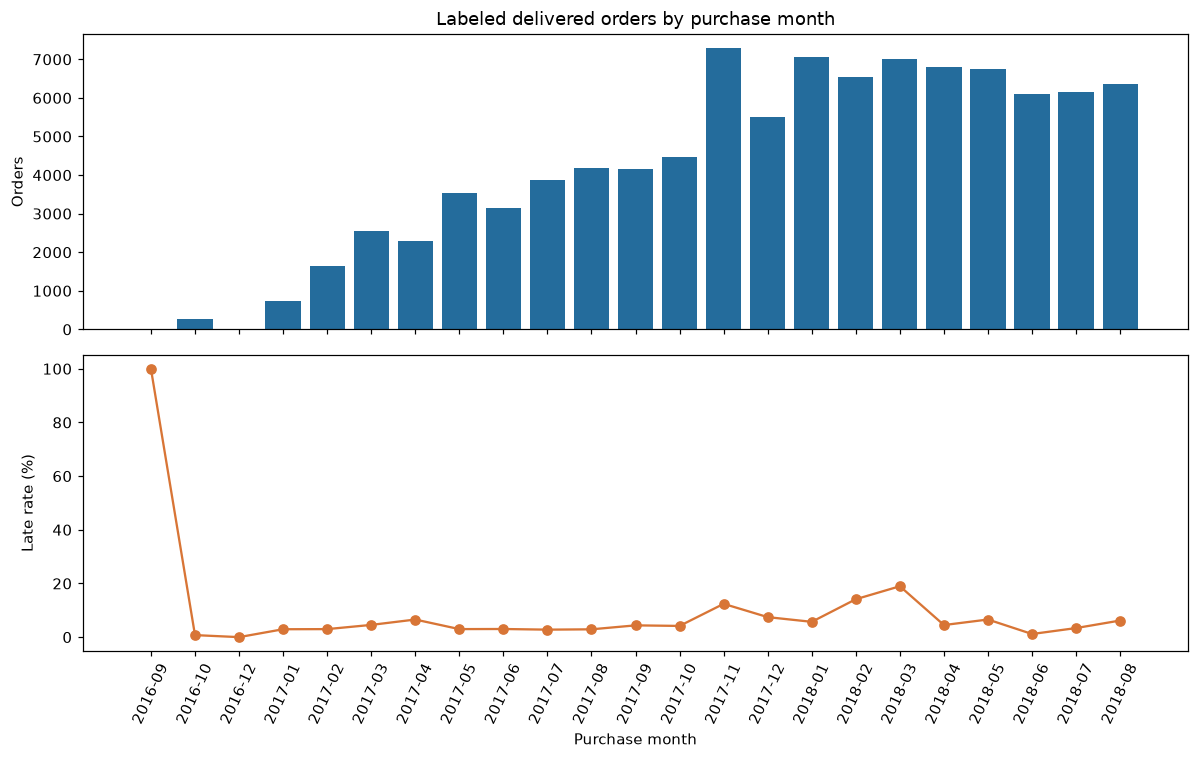

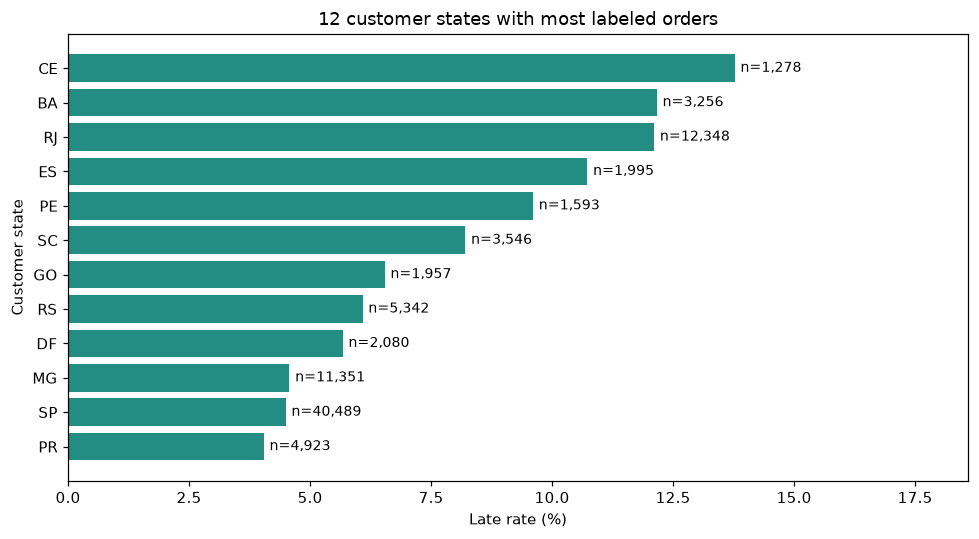

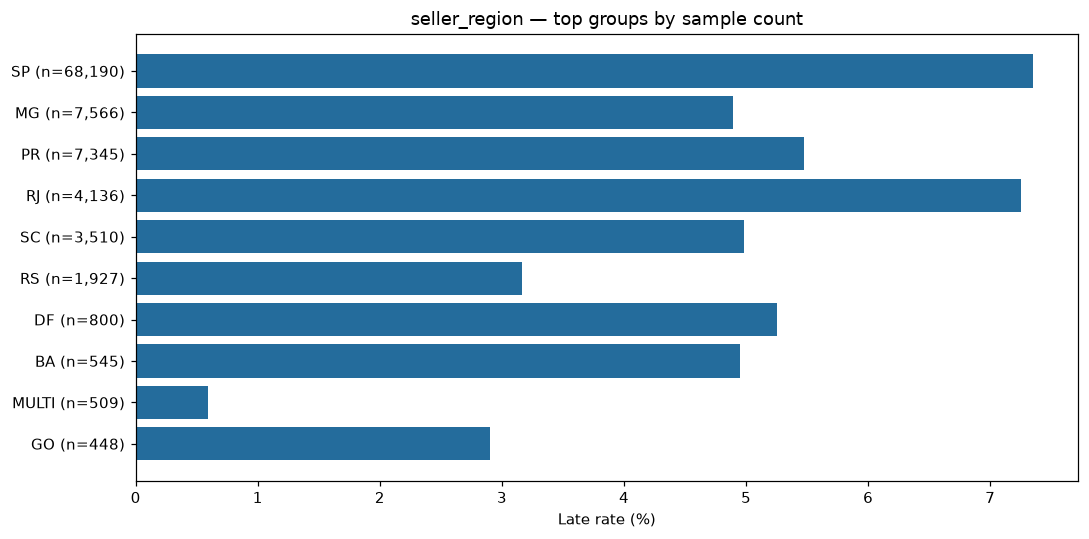

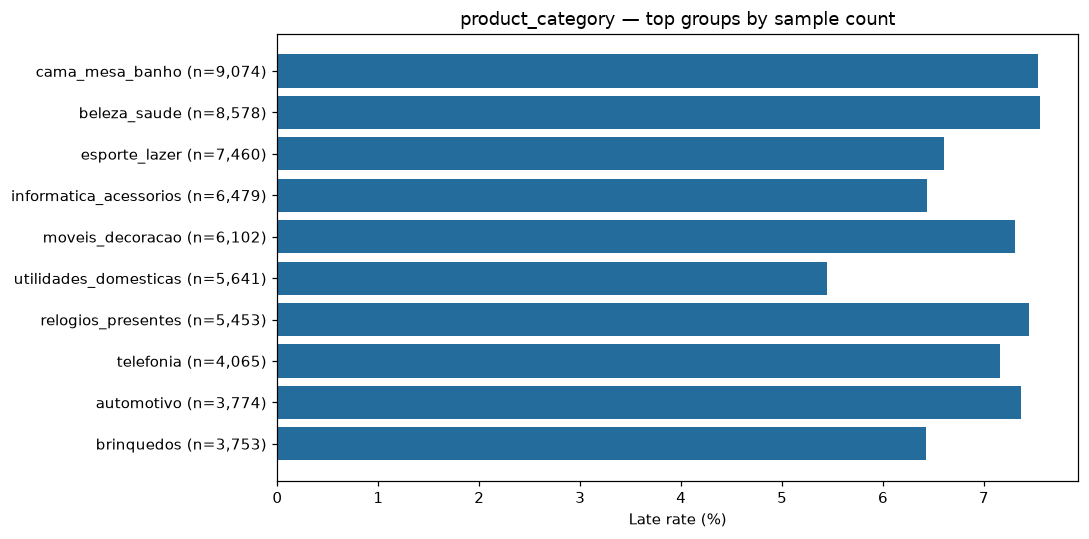

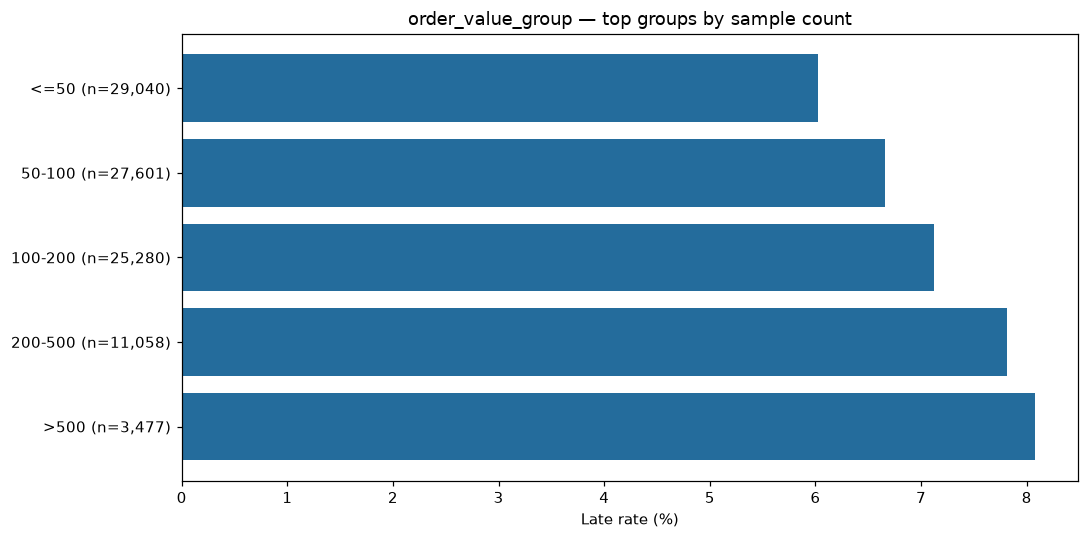

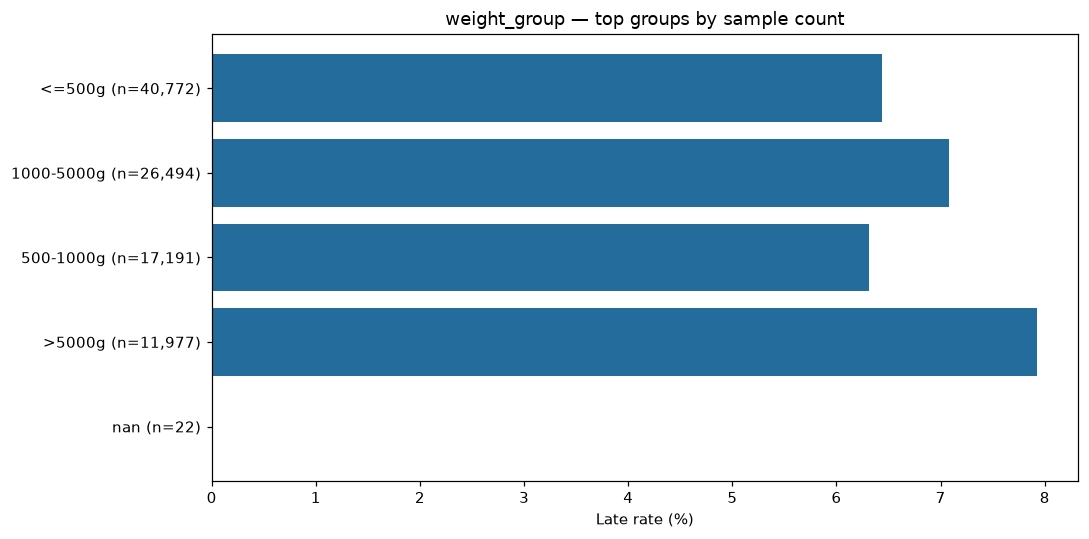

In [53]:
monthly=eda['purchase_month'].sort_values('purchase_month')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].bar(monthly['purchase_month'].astype(str),monthly['orders'],color='#246C9C')
axes[0].set(ylabel='Orders',title='Labeled delivered orders by purchase month')
axes[1].plot(monthly['purchase_month'].astype(str),100*monthly['late_rate'],marker='o',color='#D87536')
axes[1].set(ylabel='Late rate (%)',xlabel='Purchase month')
axes[1].tick_params(axis='x',rotation=65)
fig.tight_layout(); fig.savefig(FIGURES/'ch03_monthly.png',bbox_inches='tight'); plt.show()
state=eda['customer_state'].sort_values('orders',ascending=False).head(12).sort_values('late_rate')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(state['customer_state'],100*state['late_rate'],color='#238C83')
for i,(_,r) in enumerate(state.iterrows()):
    ax.text(100*r['late_rate']+.12,i,f"n={int(r['orders']):,}",va='center',fontsize=9)
ax.set(xlabel='Late rate (%)',ylabel='Customer state',title='12 customer states with most labeled orders')
ax.set_xlim(0,max(100*state['late_rate'])*1.35)
fig.tight_layout();fig.savefig(FIGURES/'ch03_customer_states.png',bbox_inches='tight');plt.show()
for group in ['seller_region','product_category','order_value_group','weight_group']:
    table=eda[group].sort_values('orders',ascending=False).head(10)
    labels=[f"{str(r[group])} (n={int(r['orders']):,})" for _,r in table.iterrows()]
    fig,ax=plt.subplots(figsize=(10,5))
    ax.barh(labels,100*table['late_rate'],color='#246C9C')
    ax.invert_yaxis();ax.set(xlabel='Late rate (%)',title=group+' — top groups by sample count')
    fig.tight_layout();fig.savefig(FIGURES/f'ch03_{group}.png',bbox_inches='tight');plt.show()


Nhận xét EDA: Ở nhóm khách hàng, SP có nhiều đơn nhất (40.489 đơn) nhưng tỷ lệ trễ chỉ 4,50%; RJ có 12.348 đơn và tỷ lệ trễ 12,11%; BA là 12,16% trên 3.256 đơn. Theo giá trị hàng, tỷ lệ trễ tăng từ 6,03% ở nhóm <=50 lên 8,08% ở nhóm >500 BRL. Đây là khác biệt mô tả, chưa chứng minh khu vực hoặc giá trị đơn là nguyên nhân gây trễ. Biểu đồ tháng có những mốc rất ít đơn nên không nên kết luận chỉ từ một điểm có tỷ lệ trễ cao.
# 3.5. Chuẩn bị dữ liệu bàn giao cho mô hình
Tập **an toàn tối thiểu** cho bài toán dự báo tại `order_approved_at`: tháng đặt hàng, ngày trong tuần, giờ đặt, thời gian từ đặt đến phê duyệt, bang khách. Các feature về giá/phí, estimated date, product/seller cần **xác minh thời điểm xuất hiện trước khi đưa vào model**.

Các cột `order_delivered_customer_date`, `order_delivered_carrier_date`, `order_status` cuối và `review_score` bị cấm làm đặc trưng.

Giữ thời điểm giao thực tế trong *artifact nội bộ* chỉ để đánh giá tính trưởng thành nhãn ở Ch4; không đưa cột này vào model X.

In [54]:
model_data['purchase_month_number']=model_data['order_purchase_timestamp'].dt.month
model_data['purchase_weekday']=model_data['order_purchase_timestamp'].dt.weekday
model_data['purchase_hour']=model_data['order_purchase_timestamp'].dt.hour
model_data['approval_delay_hours']=(model_data['order_approved_at']-model_data['order_purchase_timestamp']).dt.total_seconds()/3600
SAFE_FEATURES=['purchase_month_number','purchase_weekday','purchase_hour','approval_delay_hours','customer_state']
FORBIDDEN=['order_delivered_customer_date','order_delivered_carrier_date','order_status','review_score']
assert not set(SAFE_FEATURES).intersection(FORBIDDEN)
assert set(SAFE_FEATURES).issubset(model_data.columns)
assert not model_data['approval_delay_hours'].dropna().lt(0).any()
registry=[]
for feature in SAFE_FEATURES:
    registry.append({'feature':feature,'source':'customers' if feature=='customer_state' else 'orders',
                     'availability':'at_or_before_approved_at_per_group_contract','decision':'allowed_baseline',
                     'note':'No learned imputation/scaling applied here'})
for feature in ['total_price','total_freight','seller_count','item_count','avg_weight_g','seller_region',
                'product_category','total_payment','order_estimated_delivery_date','shipping_limit_date']:
    registry.append({'feature':feature,'source':'source_table_or_aggregation','availability':'needs_verification',
                     'decision':'needs_review','note':'EDA only until availability at t0 is confirmed'})
for feature in FORBIDDEN:
    registry.append({'feature':feature,'source':'orders_or_reviews','availability':'post_outcome',
                     'decision':'forbidden_as_feature','note':'Label / sample / retrospective analysis only'})
for feature in model_data.filter(like='qa_').columns:
    registry.append({'feature':feature,'source':'quality_audit','availability':'may_use_future_information',
                     'decision':'excluded_from_baseline','note':'QA only; do not automatically include flags in X'})
feature_registry=pd.DataFrame(registry)
feature_registry.to_csv(TABLES/'feature_registry.csv',index=False)
(PROCESSED/'feature_whitelist.json').write_text(json.dumps(SAFE_FEATURES,ensure_ascii=False,indent=2),encoding='utf-8')
output=PROCESSED/'orders_model_ready.csv'
model_data.to_csv(output,index=False)
base.to_csv(PROCESSED/'orders_analysis_all_status.csv',index=False)
# Kiểm tra trực tiếp file đã ghi, không chỉ DataFrame trong RAM.
check=pd.read_csv(output,dtype={'order_id':'string'})
assert len(check)==len(model_data) and check['order_id'].is_unique
assert check['is_late'].isin([0,1]).all()
assert check['is_late'].sum()==model_data['is_late'].sum()
display(feature_registry)
print('Đã xuất', len(model_data), 'đơn có nhãn; số cột:', model_data.shape[1])


,feature,source,availability,decision,note
0,purchase_month_number,orders,at_or_before_approved_at_per_group_contract,allowed_baseline,No learned imputation/scaling applied here
1,purchase_weekday,orders,at_or_before_approved_at_per_group_contract,allowed_baseline,No learned imputation/scaling applied here
2,purchase_hour,orders,at_or_before_approved_at_per_group_contract,allowed_baseline,No learned imputation/scaling applied here
3,approval_delay_hours,orders,at_or_before_approved_at_per_group_contract,allowed_baseline,No learned imputation/scaling applied here
4,customer_state,customers,at_or_before_approved_at_per_group_contract,allowed_baseline,No learned imputation/scaling applied here
5,total_price,source_table_or_aggregation,needs_verification,needs_review,EDA only until availability at t0 is confirmed
6,total_freight,source_table_or_aggregation,needs_verification,needs_review,EDA only until availability at t0 is confirmed
7,seller_count,source_table_or_aggregation,needs_verification,needs_review,EDA only until availability at t0 is confirmed
8,item_count,source_table_or_aggregation,needs_verification,needs_review,EDA only until availability at t0 is confirmed
9,avg_weight_g,source_table_or_aggregation,needs_verification,needs_review,EDA only until availability at t0 is confirmed


Đã xuất 96456 đơn có nhãn; số cột: 37


Nhận xét: Đã xuất 96.456 đơn có nhãn với 37 cột. File này chứa cả biến dự đoán, nhãn và cột phục vụ kiểm tra, nên không lấy tất cả cột trừ is_late làm X. Danh sách cơ sở có 5 biến: purchase_month_number, purchase_weekday, purchase_hour, approval_delay_hours, customer_state. Các biến giá, phí, người bán và sản phẩm cần xác minh có sẵn tại thời điểm dự báo hay không trước khi bổ sung.
## 3.5.1. Lưu từ điển dữ liệu
Xuất tên cột, kiểu dữ liệu, số lượng thiếu và vai trò của từng trường để các thành viên dùng cùng một cấu trúc.

In [55]:
MEANINGS={
'order_id':'Mã đơn hàng','customer_id':'Mã bản ghi khách hàng liên kết đơn',
'customer_unique_id':'Mã nhận diện khách hàng xuyên các đơn','order_status':'Trạng thái cuối quan sát',
'order_purchase_timestamp':'Thời điểm đặt đơn','order_approved_at':'Thời điểm phê duyệt, t0 dự báo',
'order_delivered_carrier_date':'Thời điểm bàn giao vận chuyển, hậu nghiệm',
'order_delivered_customer_date':'Thời điểm giao khách, dùng tạo nhãn',
'order_estimated_delivery_date':'Ngày giao dự kiến, dùng tạo nhãn; feature cần xác minh',
'order_item_id':'Số thứ tự item trong đơn','product_id':'Mã sản phẩm','seller_id':'Mã người bán',
'shipping_limit_date':'Hạn bàn giao vận chuyển, cần xác minh tại t0','price':'Giá item, BRL',
'freight_value':'Phí vận chuyển item, BRL','payment_sequential':'Thứ tự bản ghi thanh toán trong đơn',
'payment_type':'Loại thanh toán','payment_installments':'Số kỳ trả góp, 0 cần review',
'payment_value':'Giá trị thanh toán, BRL','review_id':'Mã đánh giá; không ép duy nhất trên toàn bảng',
'review_score':'Điểm đánh giá 1–5','review_comment_title':'Tiêu đề tùy chọn, thiếu có thể hợp lệ',
'review_comment_message':'Nội dung tùy chọn, thiếu có thể hợp lệ','review_creation_date':'Ngày tạo đánh giá',
'review_answer_timestamp':'Thời điểm trả lời đánh giá','product_category_name':'Danh mục tiếng Bồ Đào Nha',
'product_category_name_english':'Bản dịch danh mục tiếng Anh','product_name_lenght':'Độ dài tên sản phẩm, tên cột gốc',
'product_description_lenght':'Độ dài mô tả, tên cột gốc','product_photos_qty':'Số ảnh sản phẩm',
'product_weight_g':'Trọng lượng gram; <=0 chuyển NA theo chính sách đề xuất',
'product_length_cm':'Chiều dài cm','product_height_cm':'Chiều cao cm','product_width_cm':'Chiều rộng cm',
'geolocation_lat':'Vĩ độ','geolocation_lng':'Kinh độ'}
for prefix in ['customer','seller','geolocation']:
    MEANINGS[prefix+'_zip_code_prefix']='Tiền tố mã bưu chính, chuỗi 5 chữ số'
    MEANINGS[prefix+'_city']='Thành phố, chỉ chuẩn hóa chuỗi'
    MEANINGS[prefix+'_state']='Mã bang Brazil'
KEYS={'orders':['order_id'],'items':['order_id','order_item_id'],'customers':['customer_id'],
      'sellers':['seller_id'],'products':['product_id'],'payments':['order_id','payment_sequential'],
      'reviews':['review_id','order_id'],'translation':['product_category_name'],'geolocation':[]}
dictionary=[]
for name,d in clean.items():
    for c in raw[name].columns:
        dictionary.append({'table':name,'column':c,'meaning':MEANINGS.get(c,'Xem mô tả nguồn'),
                           'clean_dtype':str(d[c].dtype),'part_of_checked_key':c in KEYS[name],
                           'missing_after':int(d[c].isna().sum())})
pd.DataFrame(dictionary).to_csv(TABLES/'data_dictionary.csv',index=False)
schema=pd.DataFrame([{'column':c,'dtype':str(model_data[c].dtype),
                     'missing':int(model_data[c].isna().sum()),
                     'role':'feature' if c in SAFE_FEATURES else ('target' if c=='is_late' else 'metadata_or_EDA_NOT_X')}
                    for c in model_data.columns])
schema.to_csv(TABLES/'model_data_schema.csv',index=False)
manifest={
    'notebook_version':'lam_linh_9csv_v1',
    'source_files':source_records,
    'model_file':output.name,'model_sha256':hashlib.sha256(output.read_bytes()).hexdigest(),
    'rows':len(model_data),'columns':model_data.shape[1],'late_orders':int(model_data['is_late'].sum()),
    'late_rate':float(model_data['is_late'].mean()),'features':SAFE_FEATURES,
    'label':'DATE(actual)>DATE(estimated), delivered with approved+actual+estimated',
    'chronology_policy':'keep flags in main contract cohort; sensitivity table supplied for team review',
    'weight_policy':'nonpositive -> NA; original retained in *_raw',
    'geo_policy':'exact duplicate removal; outside broad screen excluded only from ZIP representative',
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__},
}
(PROCESSED/'data_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Data dictionary:',len(dictionary),'cột gốc. Schema:',len(schema),'cột bàn giao.')
print('SHA256 dữ liệu bàn giao:',manifest['model_sha256'])


Data dictionary: 52 cột gốc. Schema: 37 cột bàn giao.
SHA256 dữ liệu bàn giao: e4617b2827faa88efed19722f11990ac14df669fef21742e509c0a7a4f258bb9


Nhận xét: Đã tạo từ điển cho 52 cột gốc và schema cho 37 cột trong dữ liệu bàn giao. File data_manifest.json lưu lại phiên bản, số dòng, nhãn, danh sách biến và mã SHA256 để đối chiếu khi bàn giao.
# 3.6 Bàn giao và hướng dẫn viết báo cáo
- [ ] Đã tải 9 CSV và lập bảng row/column/missing/duplicates.
- [ ] Đã tổng hợp trước khi join; `assert_unique_orders` thành công.
- [ ] Đã thống kê đơn không gán nhãn, nêu rõ lý do loại.
- [ ] EDA có ít nhất biểu đồ theo tháng, bang, seller/danh mục và nhận xét sau khi chạy.
- [ ] Tạo file `orders_model_ready.csv` + ghi schema, số mẫu, danh sách feature, CSV hash/version.
- [ ] Gửi cho Trúc Chi và Vĩnh Chi, xác nhận đã nhận trong Issue #4.
- [ ] Viết 3.1–3.5 trong `reports/chapters/CH03_DATA.md` với hình bảng đánh số.

**Đầu ra chỉ mang tính nghiên cứu trên tập delivered đã có nhãn.** Phải ghi rõ selection bias và không tự giới thiệu feature ứng viên là feature hợp lệ khi chưa xác minh.

In [56]:
expected_clean=[CLEAN_DIR/(Path(filename).stem+'_clean.csv') for filename in NAMES.values()]
assert all(p.is_file() for p in expected_clean)
assert model_data['order_id'].notna().all() and model_data['order_id'].is_unique
assert len(model_data)+exclusion_table['excluded_orders'].sum()==len(orders)
assert not model_data['is_late'].isna().any()
assert set(SAFE_FEATURES).isdisjoint(FORBIDDEN)
# Xác nhận dữ liệu gốc không bị sửa trong suốt quy trình.
for source in source_records:
    assert hashlib.sha256((RAW/source['file']).read_bytes()).hexdigest()==source['sha256']
print('PASS: 9 bảng sạch, khóa/mẫu/nhãn nhất quán, whitelist riêng, raw nguyên trạng.')
print('Lưu ý: PASS không có nghĩa mọi bất thường đã được giải quyết; xem cleaning_log và thống nhất chính sách với nhóm.')


PASS: 9 bảng sạch, khóa/mẫu/nhãn nhất quán, whitelist riêng, raw nguyên trạng.
Lưu ý: PASS không có nghĩa mọi bất thường đã được giải quyết; xem cleaning_log và thống nhất chính sách với nhóm.


Kết luận: Notebook đã chạy đến bước kiểm tra cuối và báo PASS: có đủ 9 bảng sạch, khóa đơn hàng không trùng, nhãn hợp lệ và dữ liệu gốc không bị ghi đè. Kết quả này xác nhận quy trình chạy nhất quán, không có nghĩa tất cả trường hợp bất thường đã được giải quyết; các cờ QA cần được nhóm xem trước khi huấn luyện mô hình.